In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
import numpy as np

In [ ]:
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

In [ ]:
from Methods import quantile, expectile, weights

In [ ]:
# Poor environment
env = TwoArmedBandit(rew=1, pun=-1, pA=0.7, pB=0.3)

In [ ]:
mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                 learning_rates=0.1, discount_factors=0, 
                 choice_intensities=4, method='mean', Rmin=-2, Rmax=2, use_prefactor=False)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
X = 0.5 * np.ones((1, 3, 2))
X[0, 0, 0] = 0.8
X[0, 0, 1] = 1 - X[0, 0, 0]

In [ ]:
dist = mae.Qisaq(X)

In [ ]:
gpoints = mae.gridpoints
wdth = mae.gridwidth

(0.0, 0.27191781997680664)

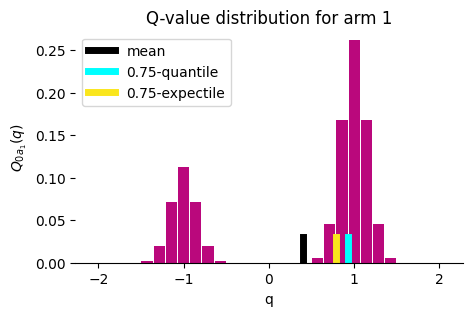

In [ ]:
s = 0
a = 0
fig, ax = plt.subplots(1, 1, figsize=(5,3))
ax.spines[['right', 'top', 'left']].set_visible(False)
ax.bar(gpoints, dist[0,s,a,:], width=0.92*wdth, color='#ba087c')
mQ = np.dot(gpoints, dist[0,s,a,:])
q = quantile(0.75, dist, gpoints)
qQ = q[0,s,a]
e = expectile(0.75, dist, gpoints)
eQ = e[0,s,a]
ax.plot([mQ, mQ], [0.0, 0.03], c='black', lw=5, label='mean')
ax.plot([qQ, qQ], [0.0, 0.03], c='cyan', lw=5, label='0.75-quantile')
ax.plot([eQ, eQ], [0.0, 0.03], c='#fae61d', lw=5, label='0.75-expectile')
ax.set_xlabel("q")
ax.set_ylabel(r'$Q_{0a_{1}}(q)$')
ax.set_title("Q-value distribution for arm 1")
ax.legend()
ax.set_ylim([0, np.max(dist[0,s,a,:])+0.01])

In [ ]:
w = np.ones(len(gpoints))
upper = gpoints >= 0
w[upper] = 2
new_dist = weights(w, dist, gpoints)

Text(0.5, 1.0, 'Q-value distribution for arm 1')

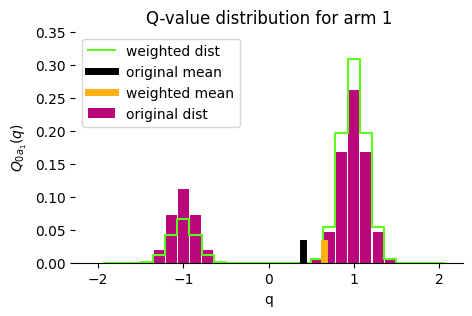

In [ ]:
s = 0
a = 0
fig, ax = plt.subplots(1, 1, figsize=(5,3))
ax.spines[['right', 'top', 'left']].set_visible(False)
ax.bar(gpoints, dist[0,s,a,:], width=0.9*wdth, color='#ba087c', label='original dist')
ax.step(gpoints+wdth/2, new_dist[0,s,a,:], color='#5dfa1d', label='weighted dist')
mQ = np.dot(gpoints, dist[0,s,a,:])
mwQ = np.dot(gpoints, new_dist[0,s,a,:])
ax.plot([mQ, mQ], [0.0, 0.03], c='black', lw=5, label='original mean')
ax.plot([mwQ, mwQ], [0.0, 0.03], c='#ffb114', lw=5, label='weighted mean')
ax.set_xlabel("q")
ax.set_ylim([0, 0.35])
ax.legend()
ax.set_ylabel(r'$Q_{0a_{1}}(q)$')
ax.set_title("Q-value distribution for arm 1")